# Notebook 3: Análisis descriptivo y visualización

**Objetivo:** Analizar los datos limpios para responder a la pregunta de fondo del proyecto: **¿qué clientes suscriben el depósito a plazo y qué factores se asocian a ello?**

In [133]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [3]:
bank_customers = pd.read_csv ("../DatosProyecto/bbdd_final/bank_customers_limpio.csv")
bank_customers.shape

(42996, 31)

## 1. Visión general de la suscripción
¿Qué porcentaje de los clientes contactados suscribe el depósito?

Se suscriben 4844 de 42996 clientes (11.27 %)


Text(0, 0.5, 'Número de clientes')

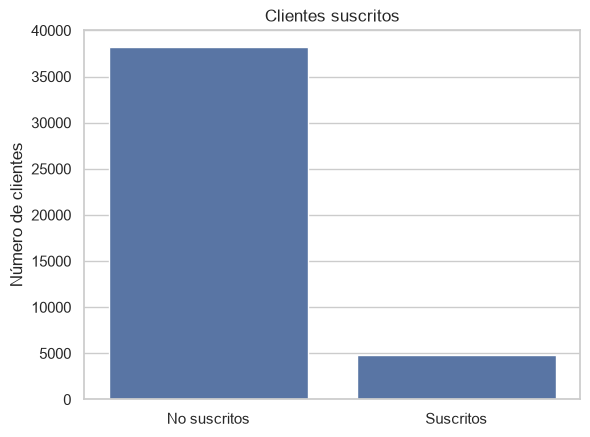

In [132]:
suscritos_bank = bank_customers["suscrito"].mean() * 100
print(f"Se suscriben {bank_customers['suscrito'].sum()} de {len(bank_customers)} clientes ({suscritos_bank.round(2)} %)")

conteo = bank_customers["y"].map({"no": "No suscritos", "yes": "Suscritos"}).value_counts()

ax = sns.barplot(x=conteo.index, y=conteo.values)
ax.set_title("Clientes suscritos")
ax.set_xlabel("")
ax.set_ylabel("Número de clientes")


Solo hay **11.27% suscritos** que se traduce en unos 4.844 clientes. Una cifra muy baja... Hay ocho veces más clientes que no se suscriben que clientes que sí.

## 2. Variables numéricas

### 2.1 Estadísticos descriptivos

In [37]:
variables_numericas = ["age", "duration", "campaign", "Income", "NumWebVisitsMonth", "Kidhome", "Teenhome"]
bank_customers[variables_numericas].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
age,42996.0,39.7,9.8,17.0,33.0,38.0,46.0,98.0
duration,42996.0,257.8,258.7,1.0,102.0,179.0,319.0,4918.0
campaign,42996.0,2.6,2.8,1.0,1.0,2.0,3.0,56.0
Income,42996.0,93244.4,50496.9,5841.0,49620.8,93052.0,136744.5,180802.0
NumWebVisitsMonth,42996.0,16.6,9.2,1.0,9.0,17.0,25.0,32.0
Kidhome,42996.0,1.0,0.8,0.0,0.0,1.0,2.0,2.0
Teenhome,42996.0,1.0,0.8,0.0,0.0,1.0,2.0,2.0


In [49]:
sin_imputar = bank_customers[bank_customers["age_rellenada"] == False]

print("Clientes con edad real:", len(sin_imputar))
print("Edad media:", round(sin_imputar["age"].mean(), 1), "| mediana:", sin_imputar["age"].median())

Clientes con edad real: 37876
Edad media: 40.0 | mediana: 38.0


### 2.2 Distribuciones
Para que las colas largas no aplasten el gráfico, recorto el eje de `duration` en 1.500 segundos (211 llamadas lo superan) y el de `campaign` en 20 contactos (170 clientes lo superan).

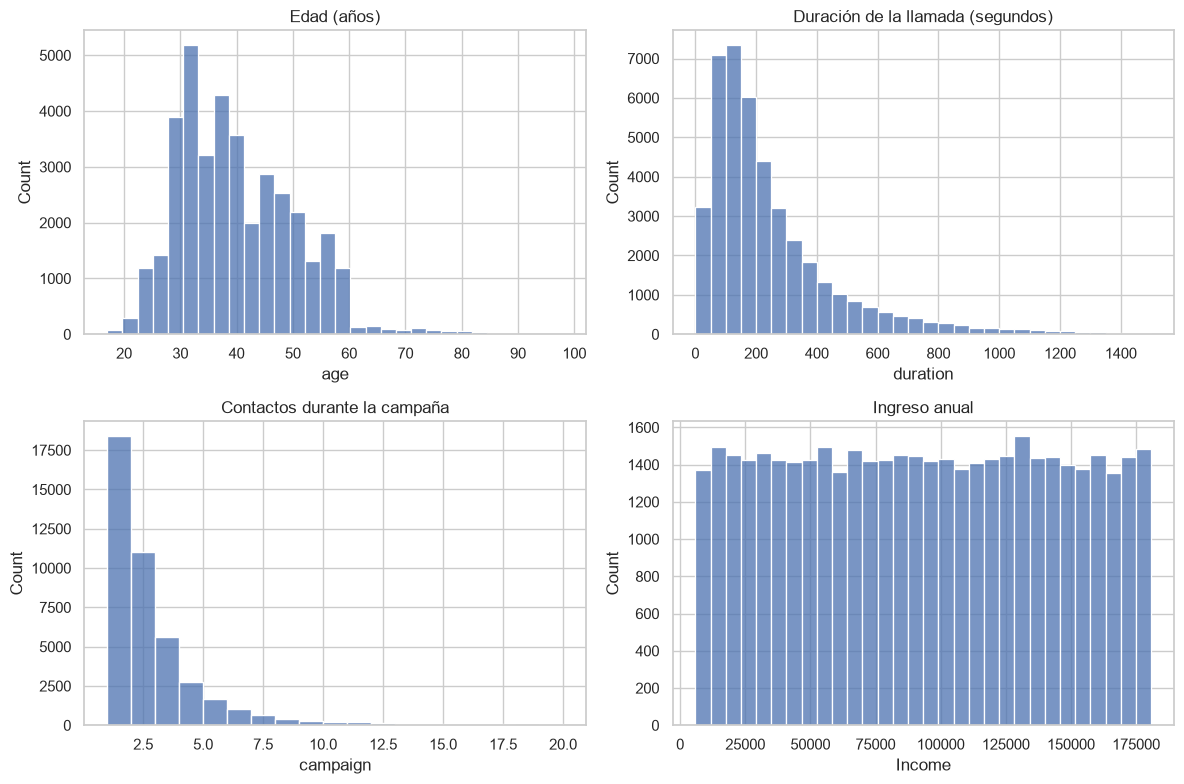

In [64]:
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(sin_imputar["age"], bins=30, ax=ejes[0, 0])
ejes[0, 0].set_title("Edad (años)")

sns.histplot(bank_customers["duration"], bins=30, binrange=(0, 1500), ax=ejes[0, 1])
ejes[0, 1].set_title("Duración de la llamada (segundos)")

sns.histplot(bank_customers["campaign"], bins=19, binrange=(1, 20), ax=ejes[1, 0])
ejes[1, 0].set_title("Contactos durante la campaña")

sns.histplot(bank_customers["Income"], bins=30, ax=ejes[1, 1])
ejes[1, 1].set_title("Ingreso anual")

plt.tight_layout()


- **Edad:** la mitad de los clientes tiene entre 33 y 46 años. La media (40) y la mediana (38) son parecidas, con una cola hacia las edades altas.
- **Duración de la llamada:** distribución muy asimétrica. La mediana es de 179 segundos (unos 3 minutos), pero la media sube a 258 por unas pocas llamadas muy largas (máximo de 82 minutos).
- **Contactos:** el 75 % de los clientes fue contactado 3 veces o menos, y unos pocos muchas más (máximo de 56).
- **Ingreso anual:** reparto bastante uniforme entre unos 6.000 y 180.000, sin concentración en ningún tramo.

### 2.3 Comparación entre quienes suscriben y quienes no

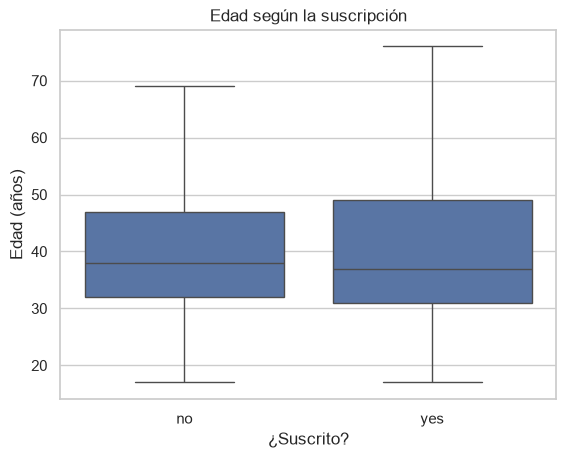

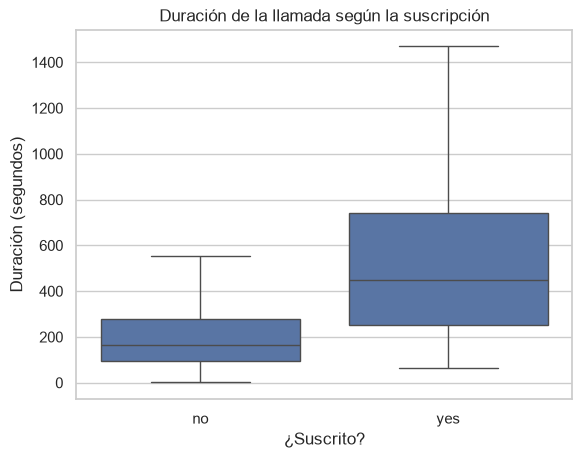

Text(0, 0.5, 'Número de contactos')

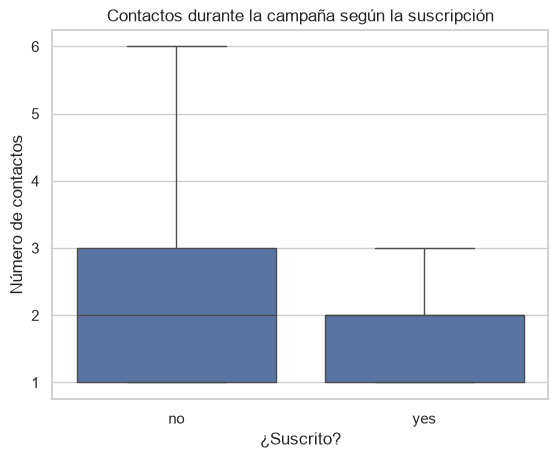

In [139]:


sns.boxplot(data=sin_imputar, x="y", y="age", order=["no", "yes"], showfliers=False)

plt.title("Edad según la suscripción")
plt.xlabel("¿Suscrito?")
plt.ylabel("Edad (años)")
plt.show()

sns.boxplot(data=bank_customers, x="y", y="duration", order=["no", "yes"], showfliers=False)

plt.title("Duración de la llamada según la suscripción")
plt.xlabel("¿Suscrito?")
plt.ylabel("Duración (segundos)")
plt.show()


sns.boxplot(data=bank_customers, x="y", y="campaign", order=["no", "yes"], showfliers=False)

plt.title("Contactos durante la campaña según la suscripción")
plt.xlabel("¿Suscrito?")
plt.ylabel("Número de contactos")

- **La duración de la llamada es la gran diferencia:** la mediana de quienes suscriben es de **449 segundos** frente a **163** de quienes no, casi el triple.
- **La edad y el número de contactos casi no cambian** entre los dos grupos (mediana de 37-38 años y de 2 contactos en ambos).

## 3. Perfil del cliente

### 3.1 Profesión

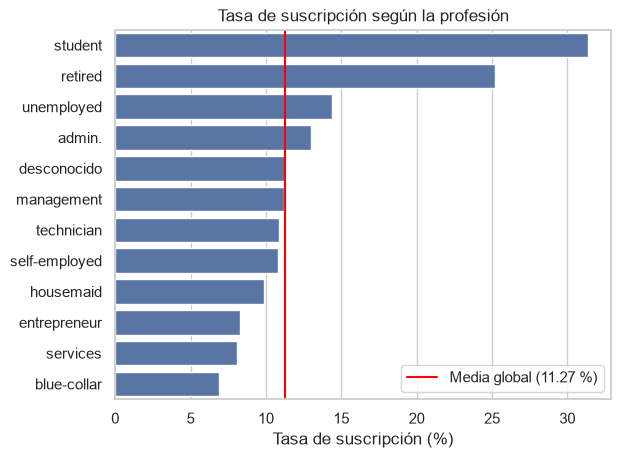

In [135]:
tasa_profesion = bank_customers.groupby("job")["suscrito"].mean() * 100
tasa_profesion = tasa_profesion.sort_values(ascending=False)


sns.barplot(x=tasa_profesion.values, y=tasa_profesion.index)
plt.axvline(suscritos_bank, color="red", linestyle="-", label=f"Media global ({suscritos_bank.round(2)} %)")
plt.title("Tasa de suscripción según la profesión")
plt.xlabel("Tasa de suscripción (%)")
plt.ylabel("")
plt.legend()
plt.show()


- Los **estudiantes (31,3 %)** y los **jubilados (25,2 %)** son, con diferencia, los que más suscriben, más del doble de la media.
- Los que menos suscriben son los trabajadores manuales (`blue-collar`, 6,9 %) y los de servicios (8,1 %).

### 3.2 Nivel de estudios
Excluyo `illiterate`, que solo tiene 18 clientes y su porcentaje no sería fiable.

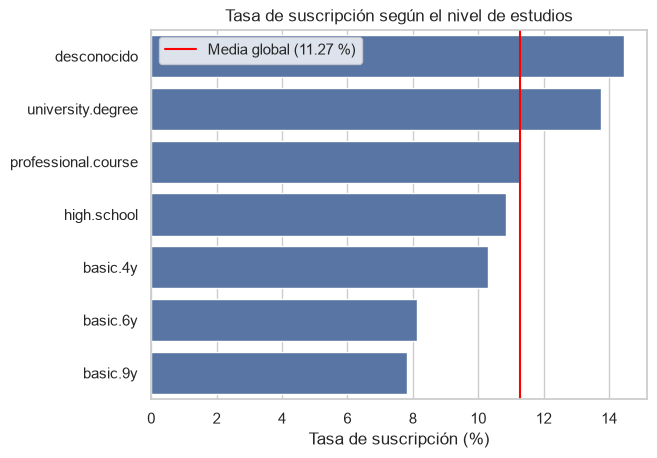

In [136]:
con_estudios = bank_customers[bank_customers["education"] != "illiterate"]

tasa_estudios = con_estudios.groupby("education")["suscrito"].mean() * 100
tasa_estudios = tasa_estudios.sort_values(ascending=False)


sns.barplot(x=tasa_estudios.values, y=tasa_estudios.index)
plt.axvline(suscritos_bank, color="red", linestyle="-", label=f"Media global ({suscritos_bank.round(2)} %)")
plt.title("Tasa de suscripción según el nivel de estudios")
plt.xlabel("Tasa de suscripción (%)")
plt.ylabel("")
plt.legend()
plt.show()

Las diferencias son moderadas. Los clientes con estudios universitarios (13,7 %) y los de nivel desconocido (14,4 %) suscriben algo más que la media, y los de estudios básicos (`basic.9y`, 7,8 %) algo menos.

### 3.3 Estado civil
Excluyo `desconocido` (85 clientes) por ser un grupo muy pequeño.

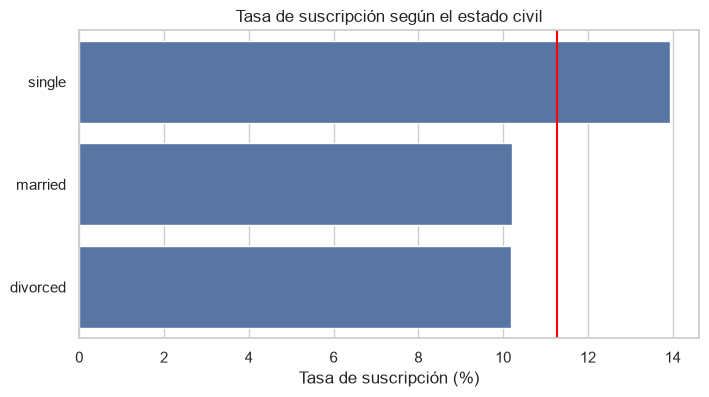

In [137]:
con_estado_civil = bank_customers[bank_customers["marital"] != "desconocido"]

tasa_civil = con_estado_civil.groupby("marital")["suscrito"].mean() * 100
tasa_civil = tasa_civil.sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=tasa_civil.values, y=tasa_civil.index)
plt.axvline(suscritos_bank, color="red", linestyle="-", label=f"Media global ({suscritos_bank.round(2)} %)")
plt.title("Tasa de suscripción según el estado civil")
plt.xlabel("Tasa de suscripción (%)")
plt.ylabel("")
plt.show()

Los **solteros (13,9 %)** suscriben algo más que los casados y los divorciados, que están igualados (10,2 % cada uno).

### 3.4 Situación financiera: `default`, `housing` y `loan`
Para estas tres columnas incluyo también a los clientes con **dato desconocido** (nulo), con `dropna=False`, porque en la limpieza decidí mantenerlos como tales. Como solo hay dos o tres grupos, muestro tablas en lugar de gráficos.

In [113]:
tasa_default = bank_customers.groupby("default", dropna=False)["suscrito"].agg(tasa="mean", clientes="size")
tasa_default["tasa"] = (tasa_default["tasa"] * 100).round(1)
tasa_default.T

default,0.0,1.0,NaN
tasa,12.9,0.0,5.2
clientes,34012.0,3.0,8981.0


In [106]:
tasa_housing = bank_customers.groupby("housing", dropna=False)["suscrito"].agg(tasa="mean", clientes="size")
tasa_housing["tasa"] = (tasa_housing["tasa"] * 100).round(1)
tasa_housing.T

housing,0.0,1.0,NaN
tasa,10.9,11.6,11.1
clientes,19475.0,22495.0,1026.0


In [94]:
tasa_loan = bank_customers.groupby("loan", dropna=False)["suscrito"].agg(tasa="mean", clientes="size")
tasa_loan["tasa"] = (tasa_loan["tasa"] * 100).round(1)
tasa_loan.T

loan,0.0,1.0,NaN
tasa,11.3,10.9,11.1
clientes,35438.0,6532.0,1026.0


- **`housing` y `loan`:** no influyen apenas. La tasa ronda el 11 % tanto si el cliente tiene hipoteca u otro préstamo como si no.
- **`default`:** solo 3 clientes tienen un impago y ninguno suscribe, un grupo demasiado pequeño para concluir nada. Lo llamativo son los **8.981 clientes sin dato**: suscriben un **5,2 %**, menos de la mitad que los que no tienen impagos (12,9 %). Esto justifica haber conservado los nulos como "desconocido", porque **faltar el dato ya es una señal**.

### 3.5 Resultado del tipo de contacto

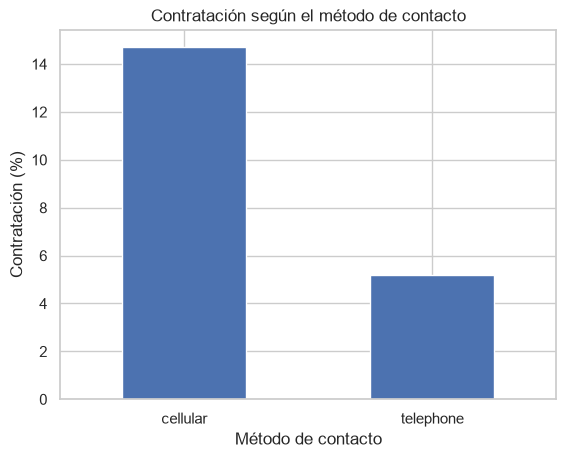

In [141]:
contratacion_contacto = bank_customers.groupby("contact")["suscrito"].mean() * 100
contratacion_contacto = contratacion_contacto.round(1)

contratacion_contacto.plot(kind="bar")

plt.title("Contratación según el método de contacto")
plt.xlabel("Método de contacto")
plt.ylabel("Contratación (%)")
plt.xticks(rotation=0)
plt.show()

## 4. Edad e ingresos
Agrupo la edad en tramos y los ingresos en cuatro cuartiles. Para la edad uso solo las filas con edad real (`sin_imputar`).

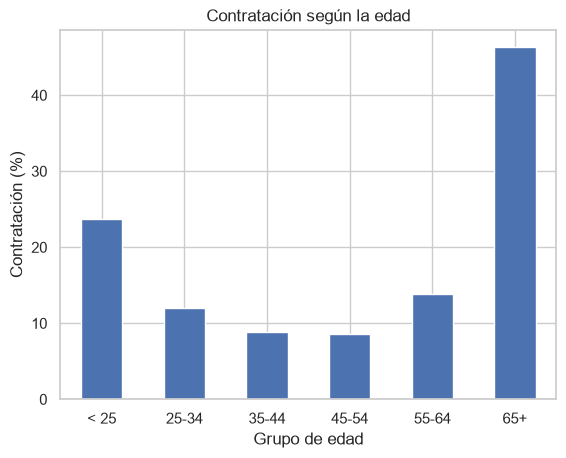

In [123]:
etiquetas_edad = ["< 25", "25-34", "35-44", "45-54", "55-64", "65+"]

sin_imputar = sin_imputar.copy()

sin_imputar["grupo_edad"] = pd.cut(
    sin_imputar["age"],
    bins=[0, 24, 34, 44, 54, 64, 110],
    labels=etiquetas_edad
)

contratacion_edad = sin_imputar.groupby("grupo_edad", observed=True)["suscrito"].mean() * 100

contratacion_edad = contratacion_edad.round(1)

contratacion_edad

contratacion_edad.plot(kind="bar")

plt.title("Contratación según la edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Contratación (%)")
plt.xticks(rotation=0)
plt.show()

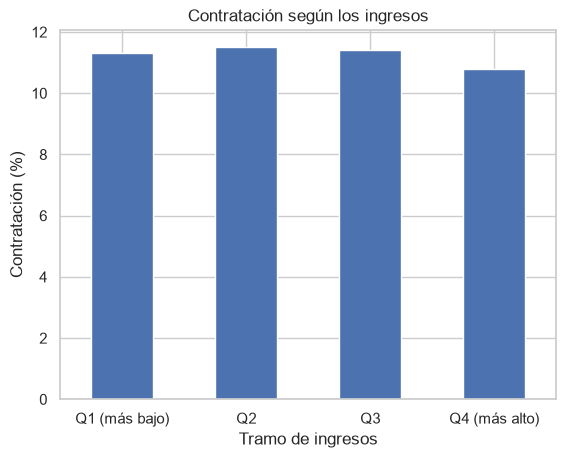

In [125]:
bank_customers = bank_customers.copy()

bank_customers["tramo_ingreso"] = pd.qcut(
    bank_customers["Income"],
    4,
    labels=["Q1 (más bajo)", "Q2", "Q3", "Q4 (más alto)"]
)

contratacion_ingresos = bank_customers.groupby("tramo_ingreso", observed=True)["suscrito"].mean() * 100

contratacion_ingresos = contratacion_ingresos.round(1)

contratacion_ingresos

contratacion_ingresos.plot(kind="bar")

plt.title("Contratación según los ingresos")
plt.xlabel("Tramo de ingresos")
plt.ylabel("Contratación (%)")
plt.xticks(rotation=0)
plt.show()

- **Edad:** la relación tiene forma de **U**. Suscriben mucho los menores de 25 (23,7 %) y, sobre todo, los **mayores de 65 (46,3 %)**, mientras que entre los 35 y los 54 años la tasa baja al 8,6-8,8 %. Al agrupar por tramos aparece lo que no se ve con una correlación lineal, que es casi nula (0,03).
- **Ingresos:** **no hay ninguna relación.** Los cuatro cuartiles tienen una tasa prácticamente idéntica (entre 10,8 % y 11,5 %), así que el nivel de ingresos no explica quién suscribe.

## 5. Indicadores económicos
Las columnas `euribor3m`, `emp.var.rate`, `nr.employed`, `cons.price.idx` y `cons.conf.idx` describen la **situación económica del momento**, no al cliente: todos los clientes contactados en el mismo periodo comparten el mismo valor. Por eso toman pocos valores distintos (por ejemplo, `nr.employed` solo 11).

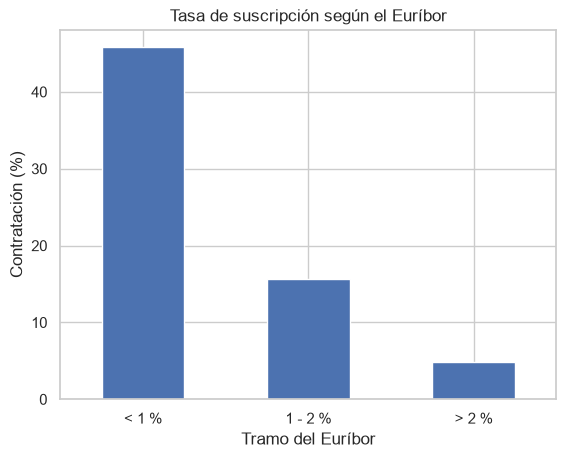

In [129]:
bank_customers["tramo_euribor"] = pd.cut(
    bank_customers["euribor3m"],
    bins=[0, 1, 2, 6],
    labels=["< 1 %", "1 - 2 %", "> 2 %"]
)

contratacion_euribor = bank_customers.groupby("tramo_euribor", observed=True)["suscrito"].mean() * 100
contratacion_euribor = contratacion_euribor.round(1)

contratacion_euribor.plot(kind="bar")

plt.title("Tasa de suscripción según el Euríbor")
plt.xlabel("Tramo del Euríbor")
plt.ylabel("Contratación (%)")
plt.xticks(rotation=0)
plt.show()

Cuando el Euríbor es **bajo (menos del 1 %)**, suscribe un **45,8 %** de los clientes, mientras que con un Euríbor por encima del 2 % solo suscribe un **4,8 %**. Tiene lógica: con tipos de interés bajos, un depósito a plazo resulta más atractivo frente a otras alternativas.

## 10. Conclusiones

**Pregunta de partida:** ¿qué clientes suscriben el depósito y qué factores se asocian a ello?

**Resultado general:** suscribe un **11,3 %** de los clientes contactados (4.844 de 42.996).

### Lo que sí se asocia con suscribir
1. **Haber suscrito en una campaña anterior:** los clientes con resultado previo `success` suscriben un **65,3 %**, frente al 8,8 % de los no contactados antes.
2. **La edad:** suscriben mucho los **mayores de 65 (46,3 %)** y los **menores de 25 (23,7 %)**, y poco los de 35 a 54 años (8,6-8,8 %). Coincide con la profesión: **estudiantes (31,3 %)** y **jubilados (25,2 %)**.
3. **El momento económico:** con el Euríbor por debajo del 1 % suscribe un 45,8 %, y por encima del 2 % solo un 4,8 %. Los indicadores económicos se mueven juntos, así que no se puede separar el efecto de cada uno.
4. **El método de contacto:** el móvil (14,7 %) casi triplica al teléfono fijo (5,2 %).
5. **La duración de la llamada:** es la variable más correlacionada (0,41), pero es una **consecuencia** del interés del cliente, no una causa, y no sirve para decidir a quién llamar.

### Lo que no se asocia con suscribir
- **Ingresos, hijos, adolescentes y visitas a la web** (datos del Excel): la tasa ronda el 11 % en todos los grupos.
- **Tener hipoteca u otro préstamo** y **el año o el mes del contacto**.

### Recomendaciones para el banco
- Priorizar a los **clientes que ya suscribieron antes**, a los **mayores de 65 años y a los jóvenes**.
- Contactar por **móvil**, y no insistir con muchas llamadas al mismo cliente.
- Planificar las campañas según el **contexto de tipos de interés**: son más efectivas cuando están bajos.